# Proyek Analisis Data: Beijing Multi-Station Air Quality (PM2.5)
- **Nama:** Asta Destian Yudha Praja
- **Email:** astadestian@gmail.com
- **ID Dicoding:** **[astadestian]**

Dataset: 12 stasiun pemantauan kualitas udara, Beijing; **1 Maret 2013–28 Februari 2017**, frekuensi per jam. Fokus indikator adalah **PM2.5 (µg/m³)**. Analisis bersifat deskriptif.

## Menentukan Pertanyaan Bisnis

**Kerangka SMART:** Specific (variabel dan lokasi jelas), Measurable (rata-rata PM2.5), Action-oriented (prioritas pemantauan), Relevant (kualitas udara), Time-bound (1 Maret 2013–28 Februari 2017).

**Definisi operasional:** Rata-rata PM2.5 dihitung dari pengamatan **per jam yang tersedia**, tidak mengimputasi nilai PM2.5 yang hilang. Setiap stasiun memiliki jumlah pengamatan valid yang sedikit berbeda sehingga besaran hasil perlu dibaca sebagai rata-rata pengamatan yang tersedia.

**Pertanyaan dibuat SMART tanpa mengasumsikan penyebab atau tren.**

- Batas analisis: 12 stasiun dan tanggal 1 Maret 2013–28 Februari 2017.
- Satuan: µg/m³, dari variabel `PM2.5` pada dataset.
- Hasil diarahkan ke prioritas investigasi dan pemantauan **bukan** klaim hubungan sebab-akibat.
- Pola bulan kalender menggunakan gabungan periode empat siklus Maret–Februari; bukan perbandingan antartahun yang durasinya tidak sama.

1. **Pertanyaan bisnis 1:** *Selama 1 Maret 2013–28 Februari 2017, bagaimana peringkat rata-rata PM2.5 per jam yang tercatat pada 12 stasiun Beijing (µg/m³), dan stasiun mana yang perlu diprioritaskan untuk pemantauan lanjutan berdasarkan rata-rata tertinggi?*
2. **Pertanyaan bisnis 2:** *Selama 1 Maret 2013–28 Februari 2017, bagaimana pola rata-rata PM2.5 menurut bulan kalender (Januari–Desember; µg/m³) pada seluruh stasiun, dan bulan apa yang perlu diprioritaskan untuk pemantauan musiman?*

**Analisis lanjutan:** Pengelompokan kuartil PM2.5 secara manual (`pandas.cut`), untuk menghitung proporsi pengamatan **di atas kuartil ketiga keseluruhan** pada setiap stasiun. Kategori ini relatif terhadap dataset, **bukan** standar indeks kualitas udara.

## Import Semua Packages/Library yang Digunakan

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import gdown
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False
})

DASHBOARD_DIR = Path("dashboard")

MONTH_NAMES = {
    1: "Jan", 2: "Feb", 3: "Mar",
    4: "Apr", 5: "Mei", 6: "Jun",
    7: "Jul", 8: "Agu", 9: "Sep",
    10: "Okt", 11: "Nov", 12: "Des"
}

## Data Wrangling

### Gathering Data

Baca **12 CSV**, satukan berdasarkan kolom-kolom konsisten, dan buat satu cap waktu (`datetime`) dari `year`, `month`, `day`, `hour`. Kolom `No` adalah nomor baris berulang antarfile dan **bukan** pengenal global; kunci yang relevan ialah (`station`, `datetime`).

In [6]:

# ID file Google Drive dataset Air Quality Dicoding
file_id = "1RhU3gJlkteaAQfyn9XOVAz7a5o1-etgr"


zip_path = Path("air_quality.zip")

if not zip_path.exists():
    downloaded = gdown.download(
        id=file_id,
        output=str(zip_path),
        quiet=False
    )

    if not downloaded:
        raise RuntimeError("Gagal mengunduh dataset dari Google Drive.")


if not zipfile.is_zipfile(zip_path):
    raise ValueError("File yang diunduh bukan ZIP yang valid.")

with zipfile.ZipFile(zip_path, "r") as zf:

    csv_files = sorted([
        name for name in zf.namelist()
        if Path(name).name.startswith("PRSA_Data_")
        and name.lower().endswith(".csv")
    ])

    print("Jumlah dataset ditemukan:", len(csv_files))

    assert len(csv_files) == 12, (
        f"Seharusnya terdapat 12 CSV, ditemukan {len(csv_files)}."
    )

    frames = [
        pd.read_csv(zf.open(name))
        for name in csv_files
    ]


df = pd.concat(frames, ignore_index=True)


df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]],
    errors="coerce"
)

print("Ukuran dataset:", df.shape)
print("Jumlah stasiun:", df["station"].nunique())
print("Periode:", df["datetime"].min(), "-", df["datetime"].max())

display(df.head())


Downloading...
From: https://drive.google.com/uc?id=1RhU3gJlkteaAQfyn9XOVAz7a5o1-etgr
To: /content/air_quality.zip
100%|██████████| 7.96M/7.96M [00:00<00:00, 22.0MB/s]


Jumlah dataset ditemukan: 12
Ukuran dataset: (420768, 19)
Jumlah stasiun: 12
Periode: 2013-03-01 00:00:00 - 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


Terkumpul **420.768** rekaman per jam dari **12** stasiun; masing-masing file memiliki **35.064** baris. Periode **2013-03-01 00:00** sampai **2017-02-28 23:00**. Perbandingan akan berfokus pada PM2.5 dan menyebutkan jumlah rekaman valid.

### Assessing Data

**Pemeriksaan kualitas data:** (1) nilai hilang, terutama PM2.5; (2) ketidaksesuaian pembacaan **PM10 < PM2.5** pada jam dan stasiun sama; (3) nilai ekstrim PM2.5 berdasarkan batas IQR; (4) duplikasi kunci (`station`, `datetime`) dan nilai negatif PM2.5. Nilai suhu/dew point negatif dapat valid, sehingga tidak selalu dianggap invalid.

In [7]:
print("Missing values per kolom:")
display(df.isna().sum().to_frame("jumlah_missing").T)
print("Duplikat station-timestamp:", df.duplicated(["station", "datetime"]).sum())
print("Nilai PM2.5 negatif:", (df["PM2.5"] < 0).sum())
inconsistent_pair = (df["PM10"].notna() & df["PM2.5"].notna() & (df["PM10"] < df["PM2.5"]))
print("PM10 < PM2.5 (indikasi ketidaksesuaian):", int(inconsistent_pair.sum()))
q1, q3 = df["PM2.5"].quantile([.25, .75]); iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
print(f"Batas atas IQR: {upper_fence:.1f}; pengamatan PM2.5 di atas batas: {int((df['PM2.5'] > upper_fence).sum()):,}")

Missing values per kolom:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
jumlah_missing,0,0,0,0,0,8739,6449,9021,12116,20701,13277,398,393,403,390,1822,318,0,0


Duplikat station-timestamp: 0
Nilai PM2.5 negatif: 0
PM10 < PM2.5 (indikasi ketidaksesuaian): 21312
Batas atas IQR: 247.5; pengamatan PM2.5 di atas batas: 19,142


**Steps to Take:**
1. Hapus baris dengan PM2.5 kosong atau negatif dari analisis **PM2.5** (tidak diisi interpolasi agar rata-rata tidak dipengaruhi asumsi).
2. Gunakan (`station`, `datetime`) untuk memeriksa/menghapus duplikasi jika ditemukan; jangan gunakan `No`.
3. Tandai ketidaksesuaian `PM10 < PM2.5`, **jangan menebak kolom mana yang salah**; keluarkan PM10 dari indikator keputusan proyek ini. Data terkait harus diverifikasi terhadap sumber instrumen jika kelak menganalisis PM10.
4. Tandai outlier berdasarkan IQR, tetapi pertahankan konsentrasi tinggi karena mungkin merupakan peristiwa polusi nyata; periksa median sebagai ukuran lebih tahan terhadap nilai ekstrim.
5. Isi kategori arah angin yang hilang sebagai "Tidak tercatat" di tabel kerja (tidak dipakai untuk pertanyaan utama).

Ditemukan **8.739** baris PM2.5 kosong (**2.08%**). **21.312** pasangan PM10–PM2.5 yang perlu diverifikasi. dan **19.142** pengamatan PM2.5 melampaui batas atas IQR **247.5 µg/m³**. Tidak ditemukan duplikat kunci stasiun-waktu dan tidak ditemukan PM2.5 negatif. Ketidaksesuaian pasangan pengukuran tidak cukup untuk memutuskan bahwa PM2.5 salah.

### Cleaning Data

Hapus hanya missing/invalid pada variabel target. Tidak menghapus nilai PM2.5 tinggi secara otomatis, sebab kejadian polusi berat adalah bagian dari fenomena yang ingin diukur. Kolom `PM10` tidak digunakan untuk kesimpulan. Simpan data beres untuk dashboard dengan kolom tanggal, stasiun, dan PM2.5.

In [8]:
clean_df = df.drop_duplicates(subset=["station", "datetime"]).copy()
clean_df["wd"] = clean_df["wd"].fillna("Tidak tercatat")
clean_df = clean_df.loc[clean_df["PM2.5"].notna() & (clean_df["PM2.5"] >= 0) & clean_df["datetime"].notna()].copy()
clean_df["outlier_iqr"] = clean_df["PM2.5"] > upper_fence
clean_df["pm10_pm25_check"] = clean_df["PM10"].notna() & (clean_df["PM10"] < clean_df["PM2.5"])
clean_df["month"] = clean_df["datetime"].dt.month
assert not clean_df["PM2.5"].isna().any()
assert not clean_df.duplicated(["station", "datetime"]).any()
main_data = clean_df[["datetime", "station", "PM2.5"]].rename(columns={"datetime":"timestamp", "PM2.5":"pm25"}).sort_values(["timestamp", "station"])
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
main_data.to_csv(DASHBOARD_DIR / "main_data.csv", index=False, date_format="%Y-%m-%d %H:%M:%S", float_format="%.3f")
print("Baris awal:", len(df), "| Baris bersih:", len(clean_df), "| Baris dikeluarkan:", len(df)-len(clean_df))
display(main_data.head())

Baris awal: 420768 | Baris bersih: 412029 | Baris dikeluarkan: 8739


,timestamp,station,pm25
0,2013-03-01,Aotizhongxin,4.0
35064,2013-03-01,Changping,3.0
70128,2013-03-01,Dingling,4.0
105192,2013-03-01,Dongsi,9.0
140256,2013-03-01,Guanyuan,4.0


Setelah menangani PM2.5 yang kosong. tersedia **412.029** observasi dengan PM2.5 terukur. Outlier IQR dipertahankan dan ditandai. tidak diperlakukan sebagai kesalahan tanpa bukti. Data ringkas yang dibutuhkan dashboard diekspor ke `dashboard/main_data.csv`. Jumlah pengamatan valid berbeda sedikit antarstasiun.

## Exploratory Data Analysis (EDA)

**EDA untuk menjawab dua pertanyaan bisnis:** agregasi `groupby(station)` untuk statistik PM2.5 setiap stasiun dan `groupby(month)` untuk pola bulan kalender. Rata-rata dan median dibandingkan untuk memastikan pembacaan pola tidak melupakan adanya nilai ekstrem. Semua estimasi berasal dari pengamatan per jam yang tercatat.

In [9]:
station_stats = (clean_df.groupby("station")["PM2.5"]
                 .agg(mean="mean", median="median", n_observations="size")
                 .sort_values("mean", ascending=False))
monthly_stats = (clean_df.groupby("month")["PM2.5"]
                 .agg(mean="mean", median="median", n_observations="size")
                 .reindex(range(1,13)))
print("Statistik stasiun:")
display(station_stats.round(2))
print("Statistik bulan kalender (gabungan empat siklus):")
display(monthly_stats.round(2))
print("Keseluruhan mean / median:",round(clean_df["PM2.5"].mean(),2),"/",round(clean_df["PM2.5"].median(),2))

Statistik stasiun:


,mean,median,n_observations
station,,,
Dongsi,86.19,61.0,34314
Wanshouxigong,85.02,60.0,34368
Nongzhanguan,84.84,59.0,34436
Gucheng,83.85,60.0,34418
Wanliu,83.37,59.0,34682
Guanyuan,82.93,59.0,34448
Aotizhongxin,82.77,58.0,34139
Tiantan,82.16,59.0,34387
Shunyi,79.49,55.0,34151


Statistik bulan kalender (gabungan empat siklus):


,mean,median,n_observations
month,,,
1,93.67,62.0,35300
2,87.57,45.0,31856
3,94.66,70.0,35293
4,72.73,61.0,33700
5,63.11,50.0,34712
6,69.09,53.0,33740
7,71.74,59.0,34716
8,53.47,41.0,35215
9,61.48,46.0,33724


Keseluruhan mean / median: 79.79 / 55.0


**Insight EDA:** Rata-rata tertinggi adalah **Dongsi (86.19 µg/m³)** dan terendah **Dingling (65.99 µg/m³)**. Berdasarkan bulan kalender, nilai tertinggi adalah **Desember (104.58 µg/m³)** dan terendah **Agustus (53.47 µg/m³)**. Angka ini menjelaskan asosiasi ruang/waktu, bukan sebab perubahan polusi.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Stasiun mana yang memiliki rata-rata PM2.5 tertinggi (2013–2017)?

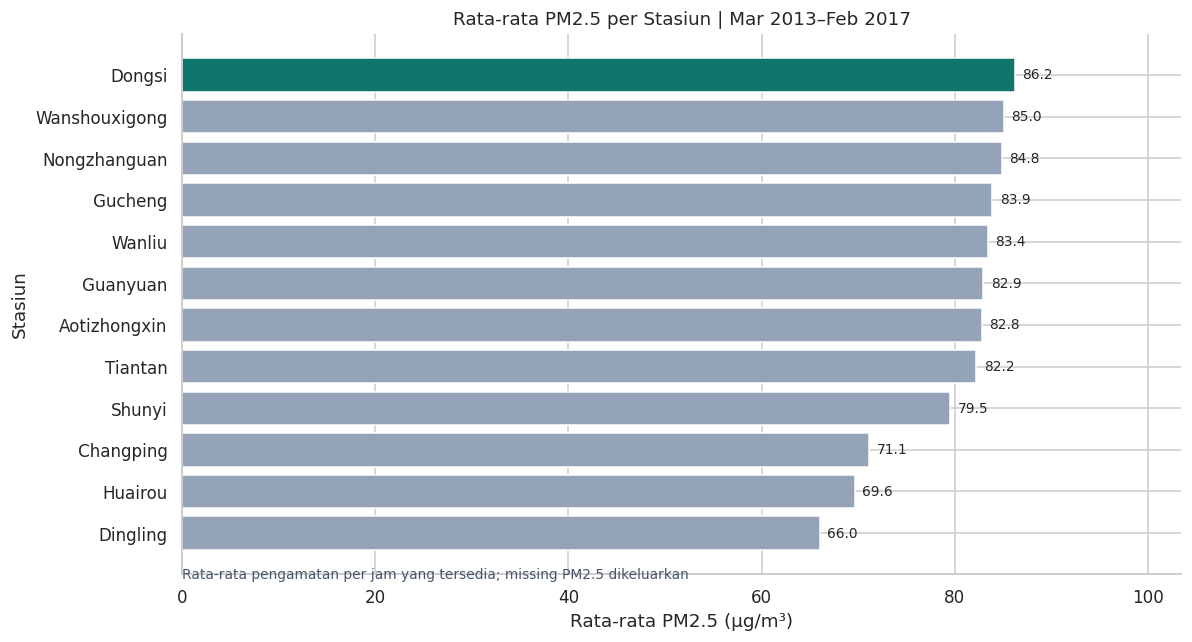

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
values = station_stats.sort_values("mean")
colors = ["#0F766E" if name == station_stats.index[0] else "#94A3B8" for name in values.index]
ax.barh(values.index, values["mean"], color=colors)
ax.set(xlabel="Rata-rata PM2.5 (µg/m³)", ylabel="Stasiun", title="Rata-rata PM2.5 per Stasiun | Mar 2013–Feb 2017")
ax.set_xlim(0, values["mean"].max()*1.2)  # bar chart: baseline nol
for i, val in enumerate(values["mean"]):
    ax.text(val+0.8, i, f"{val:.1f}", va="center", fontsize=9)
ax.text(0, -1.1, "Rata-rata pengamatan per jam yang tersedia; missing PM2.5 dikeluarkan", fontsize=9, color="#475569")
plt.tight_layout(); plt.show()

### Pertanyaan 2: Bagaimana pola rata-rata PM2.5 menurut bulan kalender?

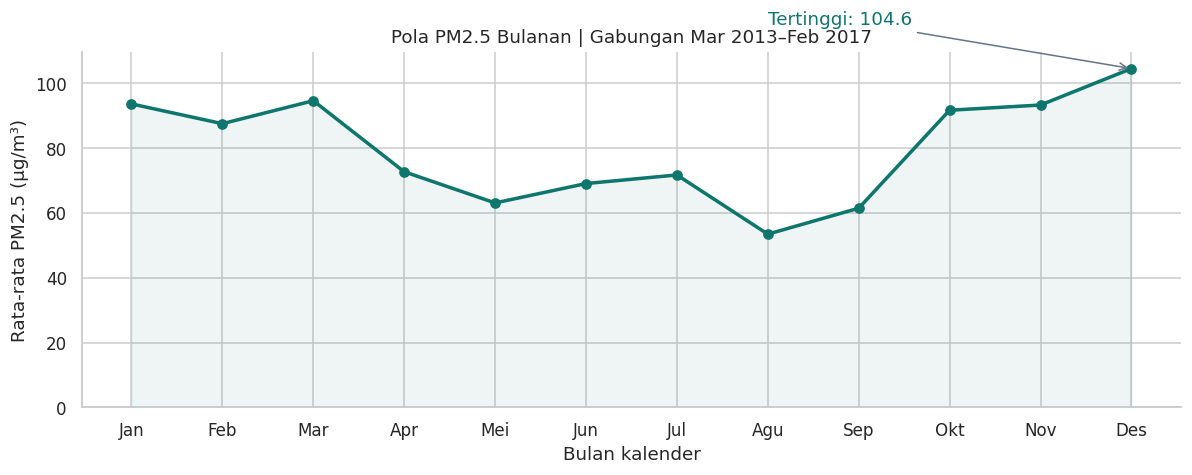

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
labels = [MONTH_NAMES[x] for x in monthly_stats.index]
ax.plot(labels, monthly_stats["mean"], marker="o", linewidth=2.3, color="#0F766E")
ax.fill_between(range(12), 0, monthly_stats["mean"].to_numpy(), alpha=0.07, color="#0F766E")
ax.set(xlabel="Bulan kalender", ylabel="Rata-rata PM2.5 (µg/m³)", title="Pola PM2.5 Bulanan | Gabungan Mar 2013–Feb 2017")
ax.set_ylim(bottom=0)
ax.annotate(f"Tertinggi: {monthly_stats['mean'].max():.1f}",
            xy=(monthly_stats['mean'].idxmax()-1, monthly_stats['mean'].max()),
            xytext=(7, monthly_stats['mean'].max()*1.13),
            arrowprops={"arrowstyle":"->", "color":"#64748B"}, color="#0F766E")
plt.tight_layout(); plt.show()

**Insight Explanatory Analysis:**
- Visualisasi pertama menempatkan **Dongsi (86.19 µg/m³)** sebagai stasiun dengan rata-rata tertinggi, disusul stasiun lain pada peringkatnya; **Dingling (65.99 µg/m³)** terendah.
- Visualisasi kedua memperlihatkan **Desember (104.58 µg/m³)** sebagai bulan kalender dengan rata-rata tertinggi dan **Agustus (53.47 µg/m³)** terendah.
- Plot batang menggunakan skala mulai 0, unit dicantumkan jelas; plot bulanan menggambarkan agregat empat siklus, **bukan** garis tren tahunan. Nilai kosong dikeluarkan tanpa imputasi.

## Analisis Lanjutan: Manual Grouping / Binning PM2.5

**Tujuan:** Menambahkan prioritas berbasis **frekuensi** konsentrasi PM2.5 relatif tinggi, bukan hanya rata-rata. Menggunakan `pandas.cut` pada batas kuartil dari **keseluruhan data valid**. Kelompok Q4 adalah PM2.5 **lebih besar daripada Q3 global**. Sebutan Q1–Q4 merupakan **kelompok relatif berdasarkan dataset**.

**Keterbatasan:** Titik ukur harian saling berkorelasi; proporsi ini deskriptif. Data tidak lengkap sempurna pada seluruh stasiun.

Batas global Q1=20.0, median=55.0, Q3=111.0 µg/m³; Q4: PM2.5 > 111.0 µg/m³


pm25_relative_bin,Q1 relatif rendah,Q2,Q3,Q4 relatif tinggi
station,,,,
Dongsi,23.32,23.74,25.51,27.44
Wanshouxigong,23.10,24.28,25.96,26.66
Wanliu,22.44,25.66,25.48,26.41
Nongzhanguan,23.62,24.54,25.44,26.40
Gucheng,21.96,25.55,26.16,26.33
Guanyuan,22.36,25.54,26.11,25.99
Aotizhongxin,23.47,24.92,25.63,25.98
Tiantan,23.31,24.90,26.23,25.56
Shunyi,26.13,24.24,24.62,25.01


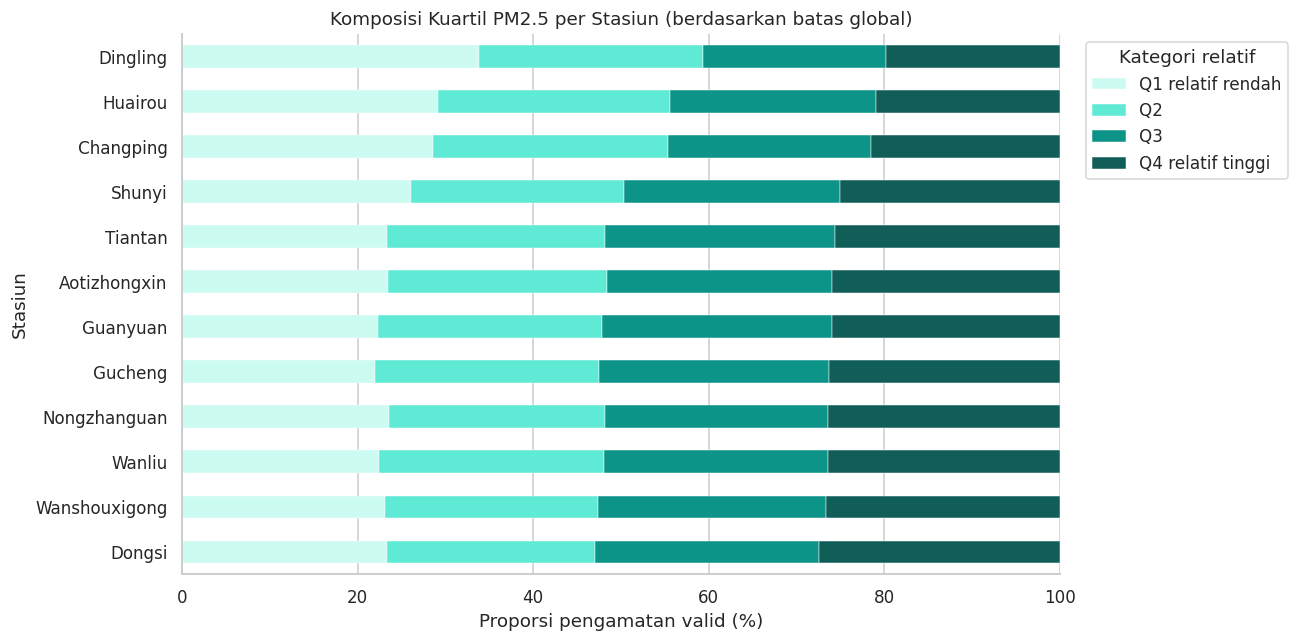

In [12]:
q25, q50, q75 = clean_df["PM2.5"].quantile([.25, .5, .75])
bins = [-np.inf, q25, q50, q75, np.inf]
labels_q = ["Q1 relatif rendah", "Q2", "Q3", "Q4 relatif tinggi"]
clean_df["pm25_relative_bin"] = pd.cut(clean_df["PM2.5"], bins=bins, labels=labels_q, include_lowest=True)
composition = (pd.crosstab(clean_df["station"], clean_df["pm25_relative_bin"], normalize="index")*100)
composition = composition.sort_values("Q4 relatif tinggi", ascending=False)
print(f"Batas global Q1={q25:.1f}, median={q50:.1f}, Q3={q75:.1f} µg/m³; Q4: PM2.5 > {q75:.1f} µg/m³")
display(composition.round(2))
fig, ax = plt.subplots(figsize=(12,6))
composition.loc[:, labels_q].plot(kind="barh", stacked=True, ax=ax,
                                  color=["#CCFBF1", "#5EEAD4", "#0D9488", "#115E59"], edgecolor="white", linewidth=.3)
ax.set(xlabel="Proporsi pengamatan valid (%)", ylabel="Stasiun", title="Komposisi Kuartil PM2.5 per Stasiun (berdasarkan batas global)")
ax.set_xlim(0,100)
ax.legend(title="Kategori relatif", bbox_to_anchor=(1.02,1),loc="upper left")
plt.tight_layout(); plt.show()

Q3 global adalah **111 µg/m³**; kategori Q4 relatif tinggi berarti **PM2.5 > 111 µg/m³**. Persentase Q4 tertinggi tercatat pada **Dongsi (27.44%)**. Angka ini membantu mengarahkan pemeriksaan/pemantauan lanjutan. Tidak dapat diartikan sebagai proporsi waktu dengan status kesehatan tertentu; belum memperhitungkan dampak kausal atau variasi pengukuran.

## Conclusion & Recommendation

1. **Jawaban pertanyaan 1 (perbedaan stasiun):** Pada rentang 1 Maret 2013–28 Februari 2017. stasiun **Dongsi** memiliki rata-rata PM2.5 tertinggi (**86.19 µg/m³**). sementara **Dingling** terendah (**65.99 µg/m³**). Perbedaan ini menunjukkan prioritas lokasi **untuk investigasi/pemantauan**. bukan menyatakan sumber polusi telah diketahui.
2. **Jawaban pertanyaan 2 (pola bulanan):** Rata-rata gabungan seluruh stasiun paling tinggi pada **Desember (104.58 µg/m³)** dan paling rendah pada **Agustus (53.47 µg/m³)**. Karena data meliputi empat siklus bulanan penuh. pola ini dapat dipakai untuk memprioritaskan bulan pemantauan. tetapi tidak menunjukkan penyebab musiman.
3. **Konteks hasil:** Seluruh ringkasan menggunakan **412.029** pengamatan PM2.5 valid. Sebanyak **8.739** observasi hilang pada indikator utama dikeluarkan; outlier tinggi tidak dihapus.

**Rekomendasi Action Item:**
1. **Prioritas lokasi:** lakukan inspeksi kelengkapan dan konsistensi sensor serta pemantauan lebih dekat di **Dongsi**. karena mean PM2.5 per jam tercatat tertinggi dibanding 11 stasiun lain selama periode analisis.
2. **Prioritas waktu:** siapkan pengecekan instrumen. pemantauan lebih sering. dan komunikasi hasil terutama menjelang **Desember** (bulan dengan rata-rata gabungan tertinggi). kemudian evaluasi ulang per tahun agar pola tidak disalahartikan sebagai kepastian.
3. **Perbaikan kualitas data:** telusuri **8.739** rekaman PM2.5 kosong dan **21.312** pasangan PM10 < PM2.5 ke sumber/instrumen sebelum membuat analisis multi-polutan. Lakukan analisis sensitivitas atas nilai ekstrem; jangan mengklaim sebab polusi hanya dari grafik deskriptif.

**Batasan:** Data historis 2013–2017 tidak menggambarkan kualitas udara saat ini; hasil bukan saran medis maupun ambang kebijakan kesehatan.